In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Fonction stable pour le logsumexp (évite les erreurs d'overflow)
def logsumexp(x, axis=None, keepdims=True):
    x_max = np.max(x, axis=axis, keepdims=True)
    return x_max + np.log(np.sum(np.exp(x - x_max), axis=axis, keepdims=keepdims))

# 2. Fonction de coût douce J_tau pour le Clustering
def soft_clustering_loss(X, centroids, tau):
    # X shape: (N, D), centroids shape: (K, D)
    X_sq = np.sum(X**2, axis=1, keepdims=True)       # (N, 1)
    C_sq = np.sum(centroids**2, axis=1)              # (K,)
    Cross = X @ centroids.T                          # (N, K)
    
    distances_sq = X_sq - 2 * Cross + C_sq          # (N, K)
    
    # J_tau = - tau * mean( logsumexp( - ||x - mu||^2 / tau ) )
    scaled_dist = -distances_sq / tau
    lse = logsumexp(scaled_dist, axis=1, keepdims=False)
    loss = -tau * np.mean(lse)
    return loss, distances_sq

# 3. Calcul du gradient analytique par rapport aux centroïdes mu_k
def soft_clustering_gradient(X, centroids, tau):
    N, D = X.shape
    K, _ = centroids.shape
    
    X_sq = np.sum(X**2, axis=1, keepdims=True)
    C_sq = np.sum(centroids**2, axis=1)
    Cross = X @ centroids.T
    distances_sq = X_sq - 2 * Cross + C_sq
    
    # Calcul des responsabilités (soft assignments) r_nk
    scaled_dist = -distances_sq / tau
    scaled_dist_stable = scaled_dist - np.max(scaled_dist, axis=1, keepdims=True)
    exp_dist = np.exp(scaled_dist_stable)
    responsibilities = exp_dist / np.sum(exp_dist, axis=1, keepdims=True) # (N, K)
    
    # Gradient de la perte par rapport aux centroïdes
    grad = np.zeros_like(centroids)
    for k in range(K):
        r_k = responsibilities[:, k:k+1]
        grad[k] = (2.0 / N) * np.sum(r_k * (centroids[k] - X), axis=0)
        
    return grad, responsibilities



Époque 30/150 - Soft Clustering Loss: 1.3434
Époque 60/150 - Soft Clustering Loss: 1.0432
Époque 90/150 - Soft Clustering Loss: 1.0379
Époque 120/150 - Soft Clustering Loss: 1.0378
Époque 150/150 - Soft Clustering Loss: 1.0378


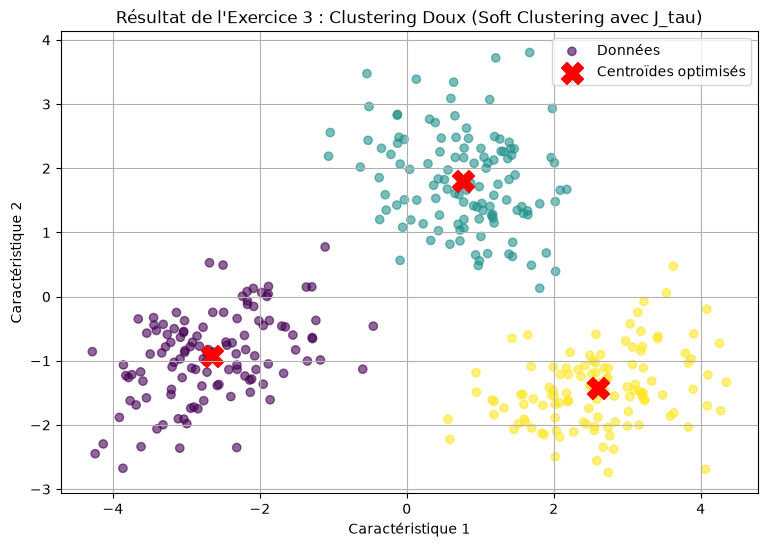

In [4]:

df_cluster = pd.read_csv("data/clustering_blobs3.csv")
X_clus = df_cluster.drop(columns=['y', 'split'], errors='ignore').values

# Initialisation de K centroïdes (ex: K=3)
K = 3
np.random.seed(42)
centroids = X_clus[np.random.choice(X_clus.shape[0], K, replace=False)]

# Paramètres
tau = 1.0
lr = 0.1
epochs = 150

loss_history = []
for epoch in range(epochs):
    loss, distances_sq = soft_clustering_loss(X_clus, centroids, tau)
    loss_history.append(loss)
    
    grad, _ = soft_clustering_gradient(X_clus, centroids, tau)
    # Mise à jour des centroïdes par descente de gradient
    centroids -= lr * grad
    
    if (epoch + 1) % 30 == 0:
        print(f"Époque {epoch+1}/{epochs} - Soft Clustering Loss: {loss:.4f}")

# Attributions finales des clusters
_, dist_final = soft_clustering_loss(X_clus, centroids, tau)
scaled_dist = -dist_final / tau
exp_dist = np.exp(scaled_dist - np.max(scaled_dist, axis=1, keepdims=True))
resp = exp_dist / np.sum(exp_dist, axis=1, keepdims=True)
clusters = np.argmax(resp, axis=1)

# Visualisation des résultats
plt.figure(figsize=(9, 6))
plt.scatter(X_clus[:, 0], X_clus[:, 1], c=clusters, cmap='viridis', alpha=0.6, label='Données')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=250, label='Centroïdes optimisés')
plt.title("Résultat de l'Exercice 3 : Clustering Doux (Soft Clustering avec J_tau)")
plt.xlabel("Caractéristique 1")
plt.ylabel("Caractéristique 2")
plt.legend()
plt.grid(True)
plt.show()

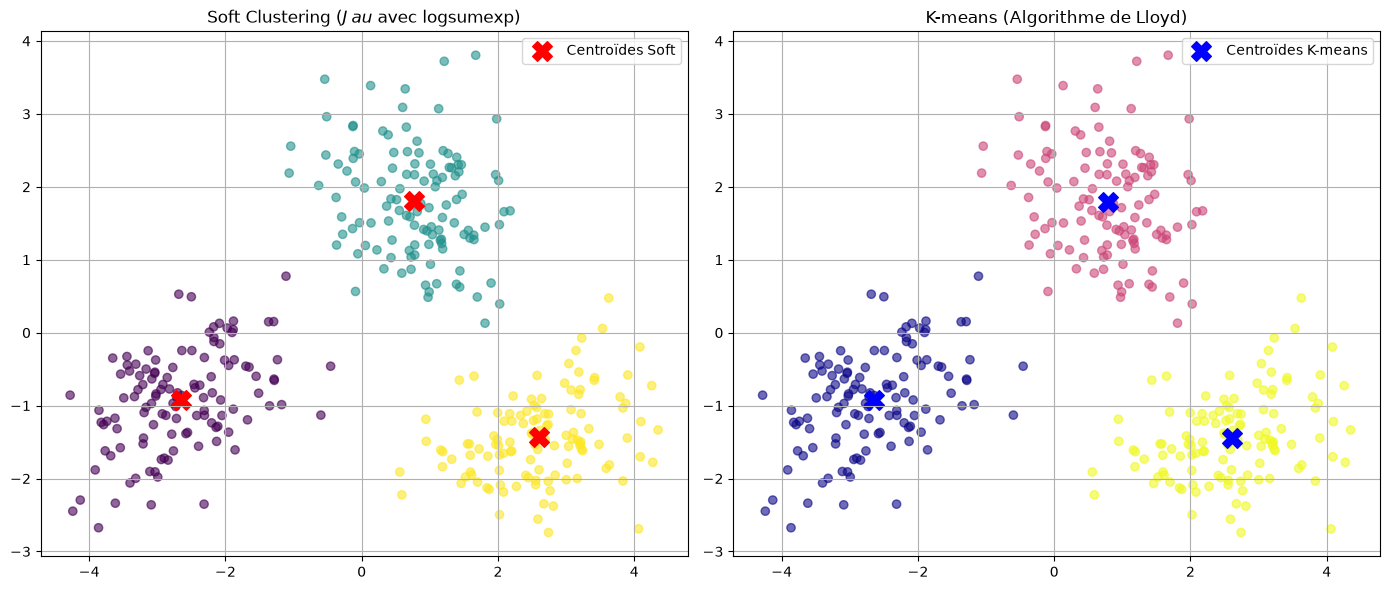

In [5]:
# Implémentation de l'algorithme de Lloyd (K-means standard) à partir de zéro avec NumPy
def kmeans_lloyd(X, K, max_iters=100, seed=42):
    np.random.seed(seed)
    # Initialisation aléatoire des centroïdes parmi les points de données
    centroids = X[np.random.choice(X.shape[0], K, replace=False)]
    
    for _ in range(max_iters):
        # 1. Étape d'affectation : calculer les distances euclidiennes et trouver le centroïde le plus proche
        X_sq = np.sum(X**2, axis=1, keepdims=True)
        C_sq = np.sum(centroids**2, axis=1)
        Cross = X @ centroids.T
        distances_sq = X_sq - 2 * Cross + C_sq
        
        labels = np.argmin(distances_sq, axis=1)
        
        # 2. Étape de mise à jour : recalculer les centroïdes comme la moyenne des points assignés
        new_centroids = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centroids[k] for k in range(K)])
        
        # Condition d'arrêt si les centroïdes ne bougent plus
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
        
    return centroids, labels

# Exécution de K-means sur les mêmes données de clustering
centroids_kmeans, labels_kmeans = kmeans_lloyd(X_clus, K=3)

# Visualisation comparative côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graphique 1 : Soft Clustering (J_tau)
axes[0].scatter(X_clus[:, 0], X_clus[:, 1], c=clusters, cmap='viridis', alpha=0.6)
axes[0].scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroïdes Soft')
axes[0].set_title("Soft Clustering ($J_\tau$ avec logsumexp)")
axes[0].legend()
axes[0].grid(True)

# Graphique 2 : K-means (Lloyd)
axes[1].scatter(X_clus[:, 0], X_clus[:, 1], c=labels_kmeans, cmap='plasma', alpha=0.6)
axes[1].scatter(centroids_kmeans[:, 0], centroids_kmeans[:, 1], c='blue', marker='X', s=200, label='Centroïdes K-means')
axes[1].set_title("K-means (Algorithme de Lloyd)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()